# What can my current GRID access do?

**Example: Worlds 2026 semifinal, Gen.G vs Invictus Gaming, November 7 (GRID series `3012979`).**
This was a BO5 that finished 3–0: there are three played games, not five observations.

This notebook uses a **real, richer Series State response retrieved with your working Open Access key**.
It does not call the File Download API. The previous file-download rejection applies to that product/series;
it does not establish a universal rule about free versus commercial accounts.

We first inspect schema, row grain and completeness, then explore bans/picks (BP), final gold differences,
player summaries and objective totals. An optional final section draws a sparse gold-difference line using
**Oracle's Elixir checkpoints**, clearly separated from GRID data.

**How to run:** select the project `.venv` kernel and Run All. The default reads cached real data and makes
no API calls, so a blank key is expected. To request a fresh snapshot, set `REFRESH_FROM_API = True` below.
A completed-series snapshot does not contain a historical gold or movement trace.

In [1]:
from pathlib import Path
import hashlib
import json
import sys
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, JSON

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(p for p in candidates if (p / "analysis/grid_client.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from analysis.grid_client import GridClient, load_api_key
from analysis.grid_free_access import (
    collect_state, flatten_state, availability_audit, grain_audit,
    schema_inventory, gold_comparison,
)

SERIES_ID = "3012979"
FOCUS_TEAM_ID = "47558"  # Gen.G; team IDs remain stable when sides change.
REFRESH_FROM_API = False
API_KEY = ""  # Optional local input; hidden input is offered when refreshing without a key.
GRID_PLATFORM = "open"
INCLUDE_ORACLE_CHECKPOINTS = True

RAW_DIR = ROOT / "data/grid/raw" / f"free_access_{SERIES_ID}"
REPORT_DIR = ROOT / "reports/grid" / f"free_access_{SERIES_ID}"
REPORT_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 100)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
TEAM_COLORS = {"Gen.G Esports": "#2878B5", "Invictus Gaming": "#DB794B"}

def save_plot(fig, filename):
    fig.savefig(REPORT_DIR / filename, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

## 1. Load a verified snapshot and inspect its provenance

Refreshing sends one authenticated Series State query and writes its exact GraphQL selection, response and
manifest to the ignored raw-data directory. It never writes the key to the manifest or outputs.
Prefer the hidden prompt or a local `.env` when refreshing; a key typed into a source cell is saved with that notebook.

The default instead checks the cached response against its saved SHA-256. **Reading an existing file does not
require API authentication.** A missing cache stops with instructions rather than generating example data.
The returned `updatedAt` and our retrieval time describe different things: source update versus download time.

In [2]:
if REFRESH_FROM_API:
    key = API_KEY.strip() or load_api_key(ROOT / ".env", prompt=True)
    state, manifest = collect_state(GridClient(key, platform=GRID_PLATFORM), SERIES_ID, RAW_DIR)
    del key
    mode = "Fresh API response"
else:
    if not (RAW_DIR / "series_state.json").is_file():
        raise FileNotFoundError("No cached state. Set REFRESH_FROM_API=True and provide your GRID key.")
    state = json.loads((RAW_DIR / "series_state.json").read_text(encoding="utf-8"))
    manifest = json.loads((RAW_DIR / "manifest.json").read_text(encoding="utf-8"))
    mode = "Cached real response; no API request"
actual_hash = hashlib.sha256((RAW_DIR / "series_state.json").read_bytes()).hexdigest()
assert actual_hash == manifest["state_sha256"], "The cached payload differs from its manifest."
assert state["id"] == SERIES_ID and manifest["series_id"] == SERIES_ID
display(pd.Series({"run_mode": mode, **manifest}).to_frame("Value"))
display(pd.DataFrame(state["teams"])[["id", "name", "score", "won"]])
display(JSON({"series_id": state["id"], "format": state["format"],
              "example_game_id": state["games"][0]["id"],
              "example_draft_action": state["games"][0]["draftActions"][0],
              "example_player": state["games"][0]["teams"][0]["players"][0]}, expanded=False))

,Value
run_mode,Cached real response; no API request
series_id,3012979
retrieved_at_utc,2026-11-14T05:02:27.309011+00:00
endpoint,https://api-op.grid.gg/live-data-feed/series-state/graphql
source,GRID Series State API
snapshot_kind,final
state_updated_at,2026-11-12T18:41:49.270Z
state_sha256,c5dcedf89284f86b5fcf1fe7177a55851c4d1380327ad902e63d2d2cb26e693f
query_sha256,725cd8ed20f4978cb97afd264740a09e05755e7a06d8d33a99aef96eea027d4e
event_file_api_used,False


,id,name,score,won
0,47558,Gen.G Esports,3,True
1,47472,Invictus Gaming,0,False


<IPython.core.display.JSON object>

## 2. Where to see the schema

GraphQL returns only the fields a query selects. The earlier small response was a subset, rather than the
complete data model. The raw folder now contains `query.graphql`, `series_state.json`, `manifest.json`, and
`series_state_schema.json` (the actual authenticated introspection result).

This cell turns that schema into a searchable table. `GameTeamStateLol` and `GamePlayerStateLol` contain
LoL-specific fields; the query selects them with GraphQL inline fragments. A field appearing in the schema
does not guarantee that it is populated for every series or title. Inspect actual coverage next.

In particular, `money` means cash currently held, `netWorth` means cash plus inventory value, and
`totalMoneyEarned` means cumulative money earned. They are different measures. We use `totalMoneyEarned`
for the gold comparison. `damageDealt` has a generic description; do not assume it means damage to champions.

Reference: [GRID's instructions for live GraphQL documentation](https://grid.helpjuice.com/how-to-get-the-gql-api-documentation).

In [3]:
schema_file = RAW_DIR / "series_state_schema.json"
schema = pd.DataFrame(columns=["type", "field", "graphql_type", "description"])
if schema_file.is_file():
    schema = schema_inventory(json.loads(schema_file.read_text(encoding="utf-8")))
    selected = ["money", "netWorth", "totalMoneyEarned", "moneyDifference", "roles", "damageDealt", "draftActions"]
    display(schema[schema["field"].isin(selected)].reset_index(drop=True))
    schema.to_csv(REPORT_DIR / "schema_inventory.csv", index=False)
else:
    display(Markdown("No cached introspection for this series folder. The selected query and actual payload are still available."))
print("Full selected query:", RAW_DIR / "query.graphql")
print("Searchable schema table:", REPORT_DIR / "schema_inventory.csv")

,type,field,graphql_type,description
0,GamePlayerStateLol,roles,[PlayerRole!]!,"Roles this Player has in this Game.\n(available from version ""3.43"")"
1,GamePlayerStateLol,money,Int!,Amount of money this Player is holding in cash.\nDepending on the Title this may represent in-ga...
2,GamePlayerStateLol,netWorth,Int!,Sum of money and inventoryValue for this Player.
3,GamePlayerStateLol,damageDealt,Int!,"The amount of damage dealt.\n(available from version ""3.23"")"
4,GamePlayerStateLol,totalMoneyEarned,Int!,"The total amount of money that was earned by this player.\n(available from version ""3.2"")"
5,GameState,draftActions,[DraftAction!]!,"A list of DraftAction, containing information about draft actions in this Game."
6,GameTeamStateLol,money,Int!,Amount of money this Team is holding in cash.\nDepending on the Title this may represent in-game...
7,GameTeamStateLol,netWorth,Int!,Sum of money and inventoryValue for this Team.
8,GameTeamStateLol,damageDealt,Int!,"The amount of damage dealt.\n(available from version ""3.23"")"
9,GameTeamStateLol,moneyDifference,Int!,"The total money earned difference to the opponent team.\n(available from version ""3.28"")"


Full selected query: D:\UIUC\Projects\LOL Analysis\Esport-League-of-Legends-Analysis\data\grid\raw\free_access_3012979\query.graphql
Searchable schema table: D:\UIUC\Projects\LOL Analysis\Esport-League-of-Legends-Analysis\reports\grid\free_access_3012979\schema_inventory.csv


## 3. Separate the observation grains

Flatten nested lists into separate pandas tables instead of repeating a team's gold across its five players.
Keys identify records at their own grain: a player appears in multiple games, and draft-action IDs restart
in each game. `draft-action-1` alone is therefore not a unique identifier.

These are final snapshots and draft decisions. A draft's `sequenceNumber` orders the selections; it is not
an in-game event timestamp. Player coordinates describe their final reported positions, not paths through the map.
Root-level series draft actions are kept separate from per-game champion drafts to avoid counting both.

In [4]:
tables = flatten_state(state)
games, teams, players, drafts, objectives = (tables[k] for k in ["games", "teams", "players", "drafts", "objectives"])
keys = {"games": "series_id + game_id", "teams": "game_id + team_id",
        "players": "game_id + player_id", "drafts": "game_id + action_id",
        "objectives": "game_id + team_id + objective_id"}
display(pd.DataFrame([{"table": name, "rows": len(frame), "grain / key": keys[name]}
                      for name, frame in tables.items()]))
display(games.sort_values("game_number"))
display(players[["game_number", "team_id", "team_name", "player_id", "player_name", "champion", "role_ids"]].head(10))
print("Separate series-level draft actions:", len(state.get("draftActions") or []))

,table,rows,grain / key
0,games,3,series_id + game_id
1,teams,6,game_id + team_id
2,players,30,game_id + player_id
3,drafts,60,game_id + action_id
4,objectives,92,game_id + team_id + objective_id


,series_id,game_id,game_number,started,finished,valid,duration_seconds,clock_seconds,patch
0,3012979,8a8bbf30-5f03-4ee0-afe4-5c6c77df38fc,1,True,True,True,2014.371,2015,16.20
1,3012979,cfcdb5a1-fddb-4046-b470-5c562c243233,2,True,True,True,1752.863,1753,16.20
2,3012979,e675f048-720d-4c4b-b79c-dc697b37d0cb,3,True,True,True,2405.057,2405,16.20


,game_number,team_id,team_name,player_id,player_name,champion,role_ids
0,1,47558,Gen.G Esports,21335,Kiin,Olaf,[]
1,1,47558,Gen.G Esports,21233,Canyon,Qiyana,[]
2,1,47558,Gen.G Esports,22132,Duro,Leona,[]
3,1,47558,Gen.G Esports,22958,Chovy,Cassiopeia,[]
4,1,47558,Gen.G Esports,22090,Ruler,Jhin,[]
5,1,47472,Invictus Gaming,23782,TheShy,Kled,[]
6,1,47472,Invictus Gaming,26680,Rookie,Syndra,[]
7,1,47472,Invictus Gaming,22073,Wei,Vi,[]
8,1,47472,Invictus Gaming,122451,JiaQi,Xayah,[]
9,1,47472,Invictus Gaming,22910,Meiko,Rakan,[]


Separate series-level draft actions: 0


## 4. Audit completeness before gameplay summaries

`availability_audit` distinguishes absent keys, explicit nulls, empty lists, observed values and observed
zeros. Empty role lists do not mean players have no role; this response simply does not provide a usable
role assignment. An empty Baron-power-play list is also different from a missing scalar.

The grain audit checks keys, rosters, game results, same-game team joins, five picks/five bans per team, and
agreement between drafted champion IDs and player champions. Blocking failures stop downstream EDA.
Reconciliation differences are reported separately for review and never silently corrected.

In [5]:
availability = availability_audit(state)
checks, reconciliation = grain_audit(tables, state)
display(availability.groupby("grain")[["absent", "null", "empty_collection", "observed", "observed_zero"]].sum()
        .rename_axis("Field-observation counts, not independent samples"))
display(availability.loc[availability[["absent", "null", "empty_collection"]].gt(0).any(axis=1)])
display(checks)
display(reconciliation)
blocking = checks[checks.severity.eq("block") & ~checks.passed]
if len(blocking):
    raise ValueError("Blocking grain/data checks failed. Review the audit before continuing.")
required = availability[(availability.grain.eq("team-game") & availability.field.isin(["totalMoneyEarned", "moneyDifference"])) |
                        (availability.grain.eq("player-game") & availability.field.isin(["totalMoneyEarned", "kills", "deaths", "killAssistsGiven", "visionScore"]))]
if required[["absent", "null"]].to_numpy().sum():
    raise ValueError("A selected analysis field is incomplete. Review coverage before aggregating it.")
review_items = checks[checks.severity.eq("review") & ~checks.passed]
if len(review_items):
    display(Markdown("**Review finding:** at least one team/player total does not reconcile. See residuals above; source values remain unchanged."))

,absent,null,empty_collection,observed,observed_zero
"Field-observation counts, not independent samples",,,,,
draft-action,0,0,0,360,0
game,0,0,0,21,0
player-game,0,0,30,510,7
team-game,0,0,3,117,12


,grain,field,rows,absent,null,empty_collection,observed,observed_zero
26,team-game,baronPowerPlays,6,0,0,3,3,0
29,player-game,roles,30,0,0,30,0,0


,check,passed,severity,detail
0,games keys,True,block,"3 rows; key = series_id, game_id"
1,teams keys,True,block,"6 rows; key = game_id, team_id"
2,players keys,True,block,"30 rows; key = game_id, player_id"
3,drafts keys,True,block,"60 rows; key = game_id, action_id"
4,Game numbers,True,block,Use the returned sequenceNumber; do not infer game number from array order.
5,Completed valid games,True,block,"This notebook analyzes completed, valid games only."
6,Two teams per game,True,block,Expected for the selected LoL series.
7,Five players per team-game,True,block,Expected for the selected LoL series.
8,Persistent team IDs,True,block,"Match team IDs to the series roster, not team-array order."
9,Player-to-team join,True,block,Many players to one team-game; no unmatched players.


,game_id,game_number,team_id,team_name,kills_residual,deaths_residual,totalMoneyEarned_residual,netWorth_residual
0,8a8bbf30-5f03-4ee0-afe4-5c6c77df38fc,1,47558,Gen.G Esports,0,0,0,0
1,8a8bbf30-5f03-4ee0-afe4-5c6c77df38fc,1,47472,Invictus Gaming,0,0,0,0
2,cfcdb5a1-fddb-4046-b470-5c562c243233,2,47558,Gen.G Esports,1,0,0,0
3,cfcdb5a1-fddb-4046-b470-5c562c243233,2,47472,Invictus Gaming,0,0,0,0
4,e675f048-720d-4c4b-b79c-dc697b37d0cb,3,47558,Gen.G Esports,0,0,0,0
5,e675f048-720d-4c4b-b79c-dc697b37d0cb,3,47472,Invictus Gaming,0,0,0,0


**Review finding:** at least one team/player total does not reconcile. See residuals above; source values remain unchanged.

### Audit interpretation and analysis boundaries

The table below is specific to the observed response, not an entitlement promise for other leagues or dates.
The current sample has only three games from one matchup. Its BP counts and player summaries are descriptive;
they cannot establish global meta strength, individual causal impact or a reliable champion win rate.

In [6]:
capabilities = pd.DataFrame([
    ("BP frequency and draft order", "Available after draft audit", "Per-game ordered pick/ban decisions with champion and team IDs"),
    ("Final gold difference", "Available", "totalMoneyEarned and moneyDifference; one endpoint per game"),
    ("Player K/D/A, gold and vision", "Available after field audit", "Final player-game summaries, not action-level attribution"),
    ("Objective totals", "Available for listed objectives", "Counts lack acquisition timestamps; an omitted type is not filled with zero"),
    ("Historical gold-over-time curve from GRID", "Unavailable in this cached response", "No sequence of historical economy snapshots was returned"),
    ("Movement paths / teamfight reconstruction", "Unavailable in this cached response", "One final position per player is insufficient"),
    ("Role-based comparisons", "Check roles coverage above", "Empty role lists are not inferred from names or roster order"),
    ("Sparse gold checkpoint line", "Optional: separate Oracle source", "10/15/20/25-minute checkpoints; not GRID telemetry"),
], columns=["Analysis", "Observed feasibility", "Boundary"])
display(capabilities)

,Analysis,Observed feasibility,Boundary
0,BP frequency and draft order,Available after draft audit,Per-game ordered pick/ban decisions with champion and team IDs
1,Final gold difference,Available,totalMoneyEarned and moneyDifference; one endpoint per game
2,"Player K/D/A, gold and vision",Available after field audit,"Final player-game summaries, not action-level attribution"
3,Objective totals,Available for listed objectives,Counts lack acquisition timestamps; an omitted type is not filled with zero
4,Historical gold-over-time curve from GRID,Unavailable in this cached response,No sequence of historical economy snapshots was returned
5,Movement paths / teamfight reconstruction,Unavailable in this cached response,One final position per player is insufficient
6,Role-based comparisons,Check roles coverage above,Empty role lists are not inferred from names or roster order
7,Sparse gold checkpoint line,Optional: separate Oracle source,10/15/20/25-minute checkpoints; not GRID telemetry


## 5. Ban/pick statistics and draft order

Join draft actions to teams using `(game_id, team_id)`, then keep only champion picks and bans. BP presence
counts distinct games in which a champion was picked or banned, divided by the number of fully audited games.
The denominator is three games, not six team-game rows or the BO5 maximum of five. A count of zero below
means an action type was absent from these audited complete drafts; it does not replace missing raw data.

Champion availability can depend on the tournament's draft rules and earlier games. Without a separately
verified availability model, this is observed selection frequency, not an availability-adjusted preference.

,champion_id,champion,pick,ban,games_present,presence_pct
40,e5a58f35-4cf1-302e-85fc-e99e161c38ab,Lulu,0,3,3,100.0
13,431d18c8-1aee-3d01-8b0a-8e46172e7761,Renata Glasc,0,3,3,100.0
0,019f1759-e612-7308-b507-a491cdafebfe,Locke,1,2,3,100.0
2,16e85313-6510-315b-83f5-13f437b191c3,Kai'Sa,0,2,2,66.7
23,8708d312-6987-35a9-90a5-db14b14babac,Orianna,0,2,2,66.7
39,e0e42b0a-7461-3143-b9a9-b70417c2384d,Pantheon,0,2,2,66.7
3,1dc7e56e-efef-35da-b827-dd31dd8812bf,Zeri,0,2,2,66.7
9,3a52e342-5377-32b9-935f-b54a66688acd,Ezreal,1,1,2,66.7
17,5fb5f03b-af85-31e8-a476-bf7f73a4819a,Nautilus,1,1,2,66.7
14,5179b7c8-f751-3f66-b40d-6671d54aab37,Nocturne,1,1,2,66.7


,game_number,team_name,side,champions
0,1,Gen.G Esports,blue,"Olaf, Qiyana, Cassiopeia, Jhin, Leona"
1,1,Invictus Gaming,red,"Vi, Kled, Syndra, Xayah, Rakan"
2,2,Gen.G Esports,blue,"Seraphine, Ashe, Lee Sin, Ahri, Gwen"
3,2,Invictus Gaming,red,"Nocturne, Lucian, Milio, Sylas, Rumble"
4,3,Gen.G Esports,red,"Nautilus, Wukong, Taliyah, Camille, Yunara"
5,3,Invictus Gaming,blue,"Alistar, Naafiri, Locke, Ezreal, Gnar"


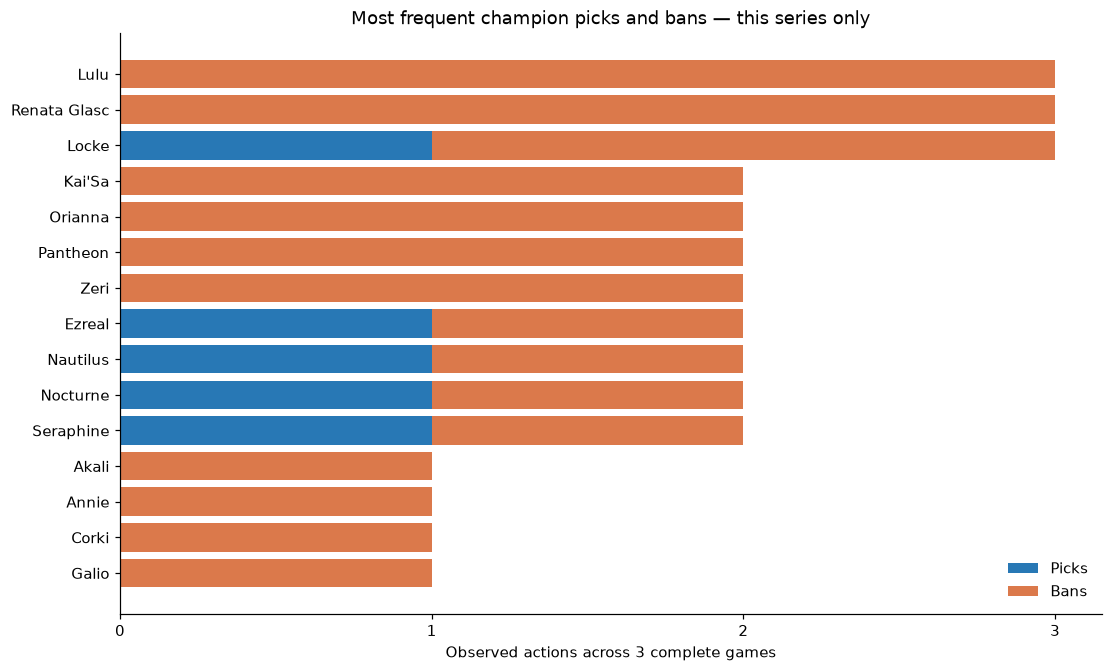

In [7]:
bp = drafts.merge(teams[["game_id", "team_id", "team_name", "side", "won"]],
                  on=["game_id", "team_id"], how="left", validate="many_to_one")
bp = bp[bp.draftable_type.eq("character") & bp.action.isin(["pick", "ban"])].copy()
n_games = len(games)
counts = bp.groupby(["champion_id", "champion", "action"]).size().unstack("action", fill_value=0)
counts = counts.reindex(columns=["pick", "ban"], fill_value=0)
presence = bp.groupby(["champion_id", "champion"])["game_id"].nunique().rename("games_present")
bp_stats = counts.join(presence).reset_index()
bp_stats["presence_pct"] = 100 * bp_stats.games_present / n_games
bp_stats = bp_stats.sort_values(["games_present", "ban", "pick", "champion"], ascending=[False, False, False, True])
display(bp_stats.head(15).round(1))
compositions = bp[bp.action.eq("pick")].sort_values("sequence").groupby(
    ["game_number", "team_name", "side"], as_index=False).agg(champions=("champion", lambda x: ", ".join(x)))
display(compositions)

top = bp_stats.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
ax.barh(top.champion, top["pick"], color="#2878B5", label="Picks")
ax.barh(top.champion, top["ban"], left=top["pick"], color="#DB794B", label="Bans")
ax.set(xlabel=f"Observed actions across {n_games} complete games", title="Most frequent champion picks and bans — this series only",
       xticks=range(n_games + 1))
ax.legend(frameon=False)
save_plot(fig, "bp_frequency.png")

### Read the actual order of each draft

The board follows the API's returned action sequence. `B` means ban and `P` means pick; each row is one
team in one game. Blank cells belong to the other team. We retain the supplied ordering and make no claim
that it encodes wall-clock time, a player's individual decision, or the rules of an inferred draft phase.

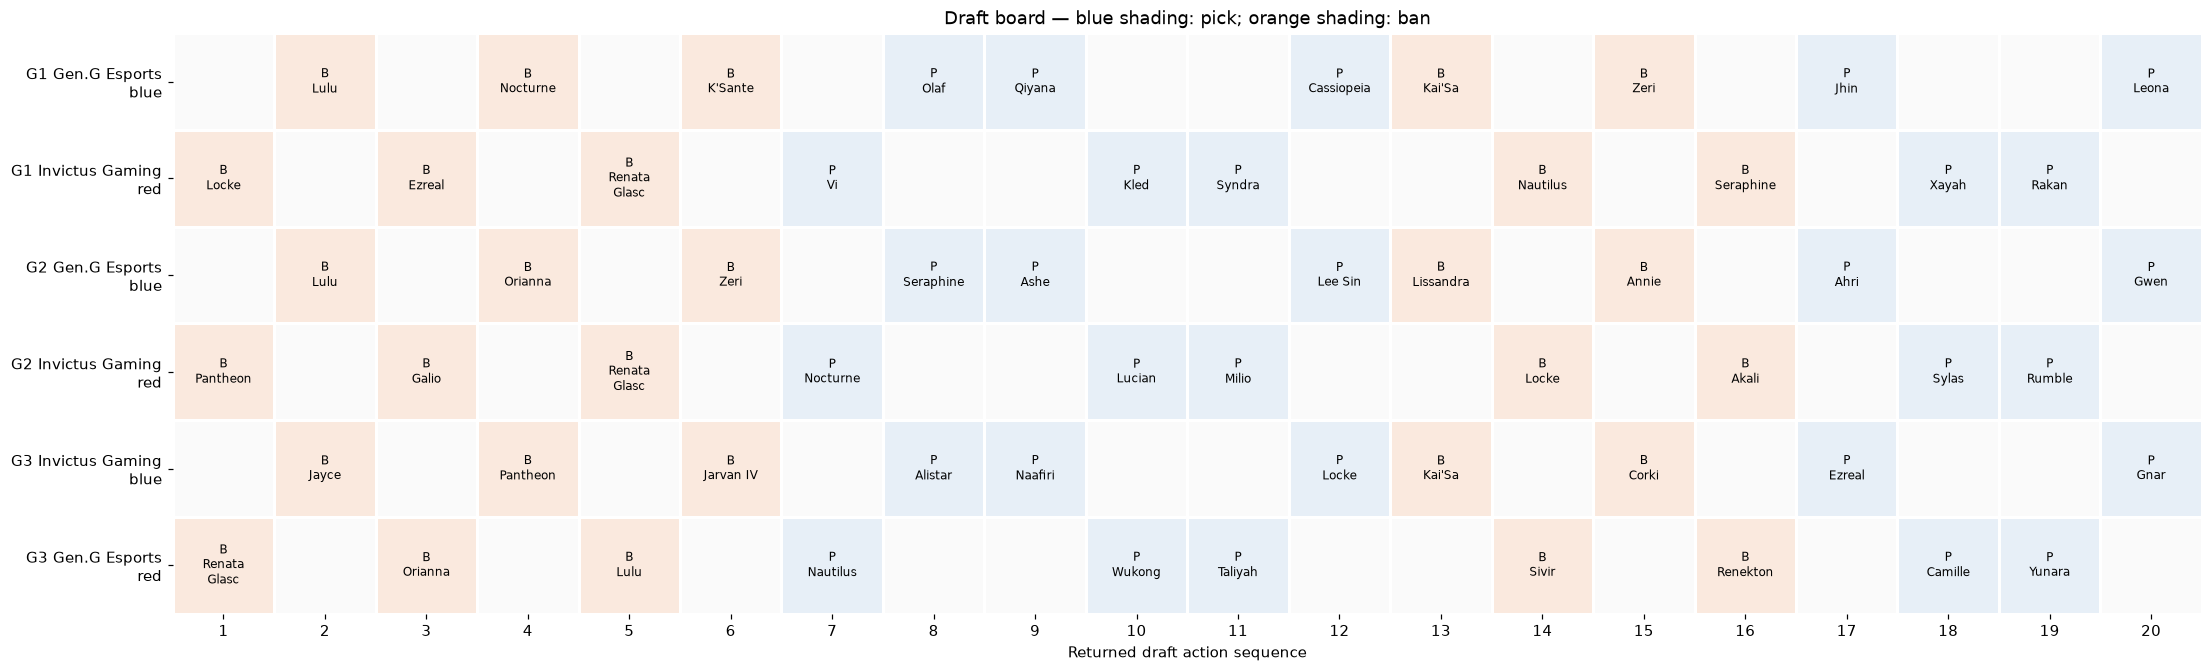

In [8]:
board_rows = teams.sort_values(["game_number", "side"])[["game_id", "team_id", "game_number", "team_name", "side"]].reset_index(drop=True)
order = sorted(bp.sequence.unique())
fig, ax = plt.subplots(figsize=(20, 6), layout="constrained")
lookup = {(r.game_id, r.team_id, r.sequence): r for r in bp.itertuples()}
for row, team in enumerate(board_rows.itertuples()):
    for column, number in enumerate(order):
        action = lookup.get((team.game_id, team.team_id, number))
        color = "#E7EFF7" if action is not None and action.action == "pick" else "#FAE9DE" if action is not None else "#FAFAFA"
        ax.add_patch(plt.Rectangle((column - .5, row - .5), 1, 1, facecolor=color, edgecolor="white", linewidth=2))
        if action is not None:
            label = ("P" if action.action == "pick" else "B") + "\n" + textwrap.fill(action.champion, 10)
            ax.text(column, row, label, ha="center", va="center", fontsize=8)
ax.set(xlim=(-.5, len(order)-.5), ylim=(len(board_rows)-.5, -.5),
       xticks=range(len(order)), xticklabels=[str(int(x)) for x in order],
       yticks=range(len(board_rows)),
       yticklabels=[f"G{r.game_number} {r.team_name}\n{r.side}" for r in board_rows.itertuples()],
       xlabel="Returned draft action sequence", title="Draft board — blue shading: pick; orange shading: ban")
ax.spines[["left", "bottom"]].set_visible(False)
save_plot(fig, "draft_board.png")

## 6. Final gold difference: feasible directly from GRID

Align both teams by persistent IDs within each game. The sign is always **Gen.G minus IG**, including Game 3
when Gen.G played red side. Compare the difference of `totalMoneyEarned` with GRID's `moneyDifference`.
`money` (unspent cash) and `netWorth` are not substituted for cumulative gold.

The bar chart contains **one final measurement per game**. Its x-axis is game number, not elapsed minutes.
Positive final gold does not reveal when the advantage was gained or which decision caused it.

,game_id,game_number,focus_side,focus_gold,opponent_gold,gold_difference,api_money_difference,difference_residual
0,8a8bbf30-5f03-4ee0-afe4-5c6c77df38fc,1,blue,73195,58595,14600,14600,0
1,cfcdb5a1-fddb-4046-b470-5c562c243233,2,blue,63754,49260,14494,14494,0
2,e675f048-720d-4c4b-b79c-dc697b37d0cb,3,red,78084,71651,6433,6433,0


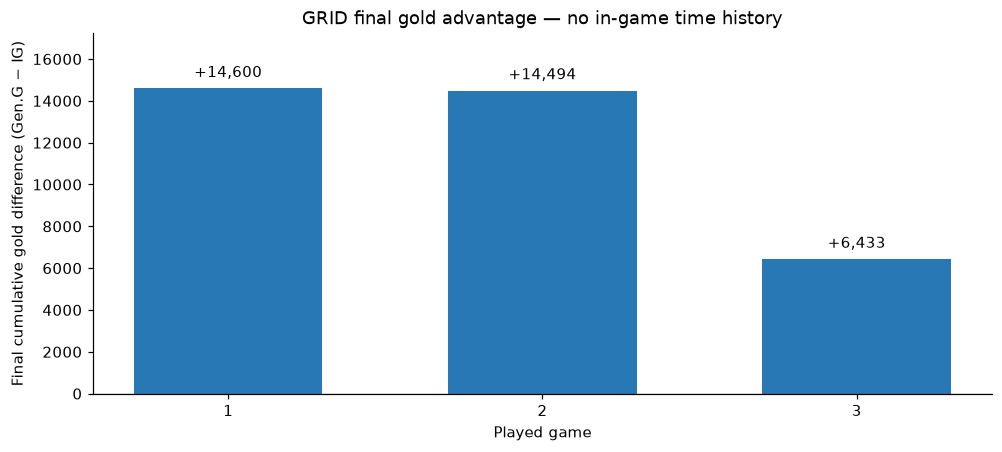

In [9]:
final_gold = gold_comparison(teams, FOCUS_TEAM_ID)
display(final_gold)
if final_gold.difference_residual.isna().any() or final_gold.difference_residual.ne(0).any():
    raise ValueError("Calculated final gold difference does not reconcile with moneyDifference.")
fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
bars = ax.bar(final_gold.game_number, final_gold.gold_difference,
              color=["#2878B5" if x >= 0 else "#DB794B" for x in final_gold.gold_difference], width=.6)
ax.bar_label(bars, labels=[f"{x:+,}" for x in final_gold.gold_difference], padding=5)
ax.axhline(0, color="#555555", linewidth=.8)
ax.set(xlabel="Played game", ylabel="Final cumulative gold difference (Gen.G − IG)",
       title="GRID final gold advantage — no in-game time history", xticks=final_gold.game_number)
ax.margins(y=.18)
save_plot(fig, "grid_final_gold_difference.png")

## 7. Basic player and objective review

Summarize kills, deaths, assists, gold and vision at player-series grain using stable player IDs. Rates below
divide series totals by the sum of the three game durations; this avoids giving a short game equal weight
to a long game. KDA uses the ratio of series totals. A zero death denominator stays undefined.

These summaries describe output and resource distribution. They do not identify tactical errors or causal
player impact. The team/player kill discrepancy remains in the audit, so we avoid deriving kill participation.
Roles are unavailable in this snapshot and generic `damageDealt` is not treated as champion damage.

Objective types overlap: `slayDragon` includes elemental dragon types. The selected table uses only generic
dragon, Baron and tower totals. An omitted objective type stays missing (`NaN`), not an assumed zero.

,team_name,player_name,games,kills,deaths,killAssistsGiven,KDA,gold_per_minute,vision_per_minute
0,Invictus Gaming,JiaQi,3,7,13,12,1.46,431.24,1.39
1,Invictus Gaming,Wei,3,8,15,17,1.67,369.86,1.89
2,Invictus Gaming,Meiko,3,0,17,23,1.35,231.61,4.13
3,Invictus Gaming,TheShy,3,6,14,15,1.50,347.42,1.35
4,Invictus Gaming,Rookie,3,15,13,13,2.15,364.82,1.21
5,Gen.G Esports,Canyon,3,14,4,37,12.75,451.90,2.10
6,Gen.G Esports,Kiin,3,14,7,23,5.29,417.40,1.66
7,Gen.G Esports,Ruler,3,23,8,33,7.00,555.62,1.85
8,Gen.G Esports,Duro,3,7,11,45,4.73,277.74,4.35
9,Gen.G Esports,Chovy,3,13,6,33,7.67,387.64,1.53


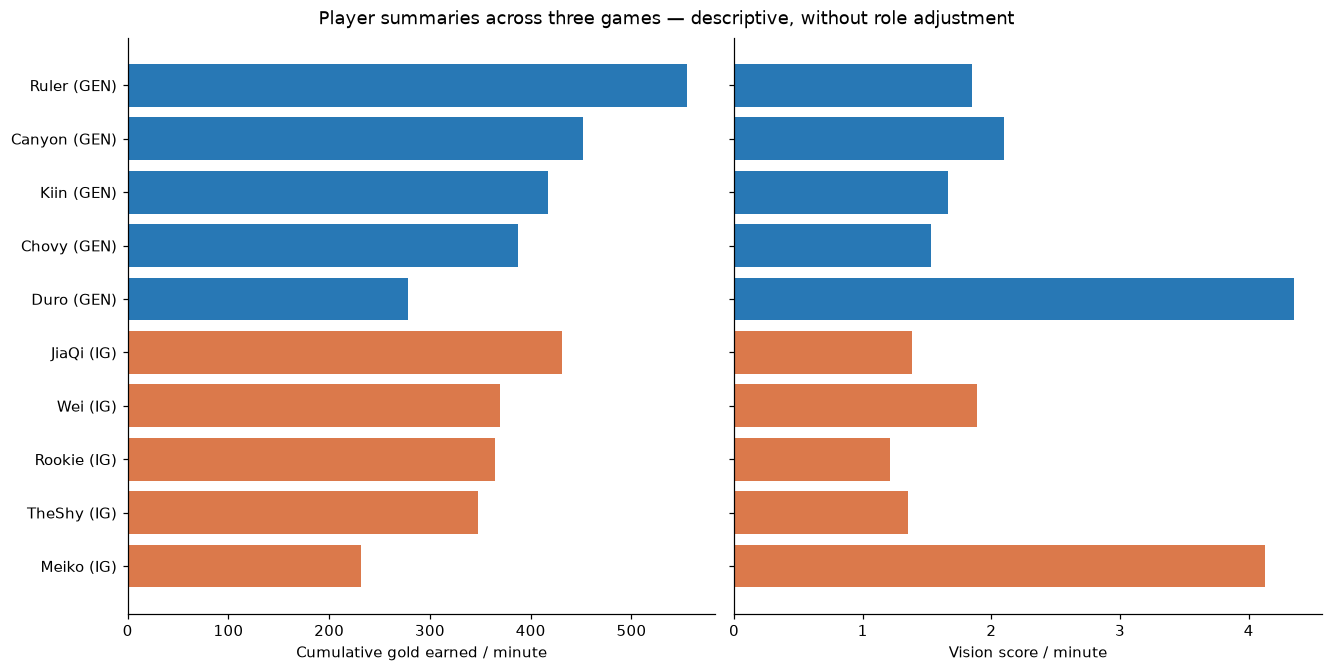

Listed objective totals; omitted types stay missing  destroyTower  slayBaron  \
game_number team_name                                                          
1           Gen.G Esports                                     9.0        1.0   
            Invictus Gaming                                   3.0        NaN   
2           Gen.G Esports                                     9.0        1.0   
            Invictus Gaming                                   1.0        NaN   
3           Gen.G Esports                                     9.0        1.0   
            Invictus Gaming                                   5.0        NaN   

Listed objective totals; omitted types stay missing  slayDragon  
game_number team_name                                            
1           Gen.G Esports                                   4.0  
            Invictus Gaming                                 1.0  
2           Gen.G Esports                                   4.0  
            Invictus Gaming                                 1.0  
3           Gen.G Esports                                   2.0  
            Invictus Gaming                                 4.0

In [10]:
player_games = players.merge(games[["game_id", "duration_seconds"]], on="game_id", validate="many_to_one")
metrics = ["kills", "deaths", "killAssistsGiven", "totalMoneyEarned", "visionScore", "duration_seconds"]
player_summary = player_games.groupby(["team_id", "team_name", "player_id", "player_name"])[metrics].agg(
    lambda s: s.sum(min_count=len(s))).reset_index()
player_summary["games"] = player_games.groupby(["team_id", "player_id"]).size().reindex(
    pd.MultiIndex.from_frame(player_summary[["team_id", "player_id"]])).to_numpy()
player_summary["KDA"] = (player_summary.kills + player_summary.killAssistsGiven) / player_summary.deaths.replace(0, np.nan)
player_summary["gold_per_minute"] = 60 * player_summary.totalMoneyEarned / player_summary.duration_seconds
player_summary["vision_per_minute"] = 60 * player_summary.visionScore / player_summary.duration_seconds
display(player_summary[["team_name", "player_name", "games", "kills", "deaths", "killAssistsGiven", "KDA", "gold_per_minute", "vision_per_minute"]].round(2))

ordered = player_summary.sort_values(["team_name", "gold_per_minute"], ascending=[True, False]).iloc[::-1]
labels = ordered.player_name + " (" + ordered.team_name.map({"Gen.G Esports": "GEN", "Invictus Gaming": "IG"}) + ")"
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True, layout="constrained")
for ax, metric, title in zip(axes, ["gold_per_minute", "vision_per_minute"], ["Cumulative gold earned / minute", "Vision score / minute"]):
    ax.barh(labels, ordered[metric], color=ordered.team_name.map(TEAM_COLORS))
    ax.set(xlabel=title)
fig.suptitle("Player summaries across three games — descriptive, without role adjustment")
save_plot(fig, "player_gold_and_vision.png")

selected_objectives = objectives[objectives.objective.isin(["slayDragon", "slayBaron", "destroyTower"])]
objective_summary = selected_objectives.pivot(index=["game_number", "team_name"], columns="objective", values="count")
display(objective_summary.rename_axis(columns="Listed objective totals; omitted types stay missing"))

## 8. Optional gold-difference line: a separate Oracle's Elixir source

**This section does not use GRID gold history.** The existing local Oracle CSV provides selected gold
checkpoints at 10, 15, 20 and 25 minutes. We select the three explicitly referenced Riot/Oracle game IDs,
use team rows only, validate both teams and the November semifinal date window, and keep the sign Gen.G − IG.
Game numbers and roster champions must agree before the cross-source comparison is accepted.

Checkpoints are eligible only if the game lasted beyond that minute, both sides report values, and the
opposite-side differences reconcile. Missing points stay missing. Lines connect observed points as a reading
aid; they do not reconstruct intervening gold, turning points or continuous telemetry. GRID final gold is
**not appended** to this other publisher's curve.

Oracle and GRID can disagree on duration or final totals because their definitions or cutoff times differ.
The comparison table reports discrepancies without claiming their cause. Turn off
`INCLUDE_ORACLE_CHECKPOINTS` for a GRID-only run.

In [11]:
oracle_points = pd.DataFrame()
oracle_checks = pd.DataFrame()
source_comparison = pd.DataFrame()
oracle_path = ROOT / "data/raw/2026_LoL_esports_match_data_from_OraclesElixir.csv"
if INCLUDE_ORACLE_CHECKPOINTS and SERIES_ID == "3012979" and oracle_path.is_file():
    reference = json.loads((ROOT / "data/grid/examples/worlds_2026_geng_ig.json").read_text(encoding="utf-8"))
    reference_ids = reference["oracle_game_ids_reference"]
    required_cols = ["gameid", "game", "date", "position", "side", "teamname", "champion", "gamelength", "totalgold"]
    checkpoint_cols = [f"golddiffat{minute}" for minute in [10, 15, 20, 25]]
    chunks = pd.read_csv(oracle_path, usecols=required_cols + checkpoint_cols, chunksize=25000)
    oracle = pd.concat([chunk[chunk.gameid.isin(reference_ids)] for chunk in chunks], ignore_index=True)
    team_map = {"Gen.G": FOCUS_TEAM_ID, "Invictus Gaming": "47472"}
    oracle["team_id"] = oracle.teamname.map(team_map)
    oracle_teams = oracle[oracle.position.eq("team")].copy()
    assert set(oracle_teams.gameid) == set(reference_ids) and len(oracle_teams) == 2 * len(games)
    assert not oracle_teams.duplicated(["gameid", "team_id"]).any() and oracle_teams.team_id.notna().all()
    assert oracle_teams.groupby("gameid").team_id.nunique().eq(2).all()
    times = pd.to_datetime(oracle_teams.date, utc=True)
    assert times.between(pd.Timestamp(reference["date_window_utc"]["gte"]), pd.Timestamp(reference["date_window_utc"]["lte"])).all()
    assert set(oracle_teams.game) == set(games.game_number)
    for number, grid_group in players.groupby("game_number"):
        other = oracle[oracle.game.eq(number) & ~oracle.position.eq("team")]
        assert len(other) == 10 and set(zip(other.team_id, other.champion)) == set(zip(grid_group.team_id, grid_group.champion))
    audit_rows, point_rows = [], []
    for number, group in oracle_teams.groupby("game"):
        assert len(group) == 2
        own = group[group.team_id.eq(FOCUS_TEAM_ID)].iloc[0]
        opponent = group[~group.team_id.eq(FOCUS_TEAM_ID)].iloc[0]
        for minute in [10, 15, 20, 25]:
            a, b = own[f"golddiffat{minute}"], opponent[f"golddiffat{minute}"]
            eligible = bool(pd.notna(own.gamelength) and pd.notna(opponent.gamelength) and min(own.gamelength, opponent.gamelength) > minute * 60)
            reported = bool(pd.notna(a) and pd.notna(b))
            reciprocal = bool(reported and np.isclose(a + b, 0))
            valid = eligible and reported and reciprocal
            audit_rows.append({"game_number": number, "minute": minute, "eligible": eligible,
                               "both_reported": reported, "reciprocal": reciprocal, "included": valid})
            point_rows.append({"game_number": number, "oracle_game_id": own.gameid, "minute": minute,
                               "gold_difference": a if valid else np.nan, "source": "Oracle's Elixir"})
    oracle_checks, oracle_points = pd.DataFrame(audit_rows), pd.DataFrame(point_rows)
    own_totals = oracle_teams[oracle_teams.team_id.eq(FOCUS_TEAM_ID)].rename(columns={"game": "game_number", "totalgold": "oracle_focus_gold", "gamelength": "oracle_seconds"})
    source_comparison = final_gold[["game_number", "focus_gold"]].merge(
        own_totals[["game_number", "oracle_focus_gold", "oracle_seconds"]], on="game_number", validate="one_to_one").merge(
        games[["game_number", "duration_seconds"]], on="game_number", validate="one_to_one")
    source_comparison["oracle_minus_grid_gold"] = source_comparison.oracle_focus_gold - source_comparison.focus_gold
    source_comparison["oracle_minus_grid_seconds"] = source_comparison.oracle_seconds - source_comparison.duration_seconds
    display(oracle_checks)
    display(source_comparison.round(3))
    print("Oracle source:", oracle_path)
else:
    display(Markdown("**Oracle checkpoint section skipped.** It is optional, needs the local 2026 CSV, and is mapped only to the selected Gen.G–IG series."))

,game_number,minute,eligible,both_reported,reciprocal,included
0,1,10,True,True,True,True
1,1,15,True,True,True,True
2,1,20,True,True,True,True
3,1,25,True,True,True,True
4,2,10,True,True,True,True
5,2,15,True,True,True,True
6,2,20,True,True,True,True
7,2,25,True,True,True,True
8,3,10,True,True,True,True
9,3,15,True,True,True,True


,game_number,focus_gold,oracle_focus_gold,oracle_seconds,duration_seconds,oracle_minus_grid_gold,oracle_minus_grid_seconds
0,1,73195,73289,2018,2014.371,94,3.629
1,2,63754,63848,1756,1752.863,94,3.137
2,3,78084,78179,2408,2405.057,95,2.943


Oracle source: D:\UIUC\Projects\LOL Analysis\Esport-League-of-Legends-Analysis\data\raw\2026_LoL_esports_match_data_from_OraclesElixir.csv


### Plot only the validated checkpoint observations

The chart can show that Gen.G was behind at the recorded checkpoints in Game 3 and still won. It cannot
locate the comeback's decisive fight: the 25-minute checkpoint and the game's end are many minutes apart.
Use event data or collected live snapshots for a finer study. No values are interpolated or filled in the data.

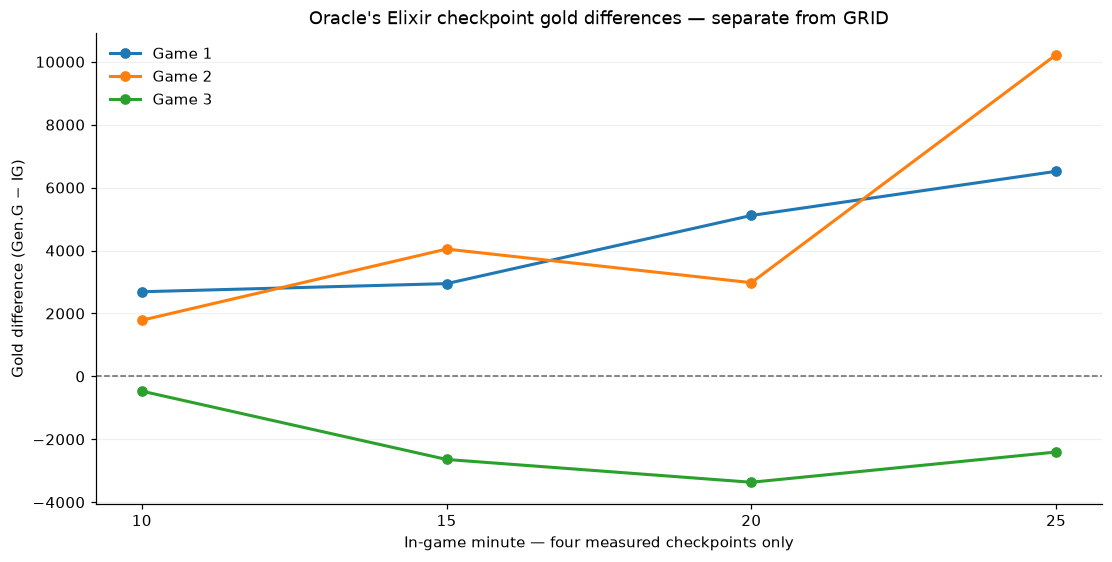

game_number,1,2,3
minute,,,
10,2690.0,1784.0,-469.0
15,2948.0,4047.0,-2641.0
20,5115.0,2978.0,-3366.0
25,6518.0,10225.0,-2405.0


In [12]:
if not oracle_points.empty:
    fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
    for number, group in oracle_points.groupby("game_number"):
        group = group.sort_values("minute")
        ax.plot(group.minute, group.gold_difference, marker="o", linewidth=2, label=f"Game {number}")
    ax.axhline(0, color="#666666", linestyle="--", linewidth=1)
    ax.set(xlabel="In-game minute — four measured checkpoints only", ylabel="Gold difference (Gen.G − IG)",
           title="Oracle's Elixir checkpoint gold differences — separate from GRID", xticks=[10, 15, 20, 25])
    ax.legend(frameon=False)
    ax.grid(axis="y", alpha=.18)
    save_plot(fig, "oracle_checkpoint_gold_difference.png")
    display(oracle_points.pivot(index="minute", columns="game_number", values="gold_difference"))
else:
    display(Markdown("No validated Oracle checkpoint points were loaded; no historical gold line is generated."))

## 9. Save the results and decide what to explore next

Export the full audit and tidy tables so you can inspect all records beyond the previews. These outputs
contain match data and provenance, never credentials. The notebook also retains all rendered charts.

Useful next projects with this access are a larger BP sample, pick order by team/side, champion-pool diversity,
gold and vision summaries, and objective control summaries after checking coverage in each new series.
Expand with Central Data discovery and one state query per selected series, caching each result; do not
assume that coverage here extends to every competition.

A future gold-over-time chart could come from **live snapshots you collect while an accessible series is
actually running**, if your account allows live state. Save each response with retrieval time, game ID and
game clock, verify that the source state advances, and deduplicate unchanged updates. This has polling
resolution, not event resolution, and cannot recover earlier history. GRID currently documents Open Access
limits of six state requests per minute per series; check your account limits before designing a collector.
This notebook does not start a polling loop.

Sources: [Series State overview](https://grid.helpjuice.com/en_US/cloud9-x-jetbrains-hackathon/what-is-the-series-state-api),
[GraphQL documentation](https://grid.helpjuice.com/how-to-get-the-gql-api-documentation),
[API rate limits](https://grid.helpjuice.com/rate-limits-for-products),
[Oracle's Elixir downloads](https://oracleselixir.com/tools/downloads).

In [13]:
exports = {**tables, "availability_audit": availability, "grain_audit": checks,
           "team_player_reconciliation": reconciliation, "capabilities": capabilities,
           "bp_actions": bp, "bp_statistics": bp_stats, "final_gold_difference": final_gold,
           "player_series_summary": player_summary, "objective_summary": objective_summary.reset_index()}
if not oracle_points.empty:
    exports.update({"oracle_checkpoints": oracle_points, "oracle_checkpoint_audit": oracle_checks,
                    "cross_source_final_comparison": source_comparison})
for name, frame in exports.items():
    frame.to_csv(REPORT_DIR / f"{name}.csv", index=False)
gold_values = ", ".join(f"G{r.game_number}: {r.gold_difference:+,}" for r in final_gold.itertuples())
findings = (
    f"# Verified GRID access: series {SERIES_ID}\\n\\n"
    f"Source: {manifest['source']}; endpoint: {manifest['endpoint']}.\\n"
    f"Retrieved: {manifest['retrieved_at_utc']}; source update: {manifest['state_updated_at']}.\\n\\n"
    f"- {len(games)} completed games, {len(teams)} team-game rows, {len(players)} player-game rows.\\n"
    f"- {len(bp)} audited champion draft actions; BP denominator is {n_games} games.\\n"
    f"- Final cumulative gold differences, Gen.G minus IG: {gold_values}.\\n"
    f"- {len(review_items)} team/player reconciliation checks require review; raw totals are preserved.\\n"
    "- Player roles are not inferred from empty role lists.\\n"
    "- Final positions and final economy do not supply historical trajectories.\\n"
    f"- Optional Oracle checkpoint observations: {int(oracle_points.gold_difference.notna().sum()) if not oracle_points.empty else 0}; separate publisher and source.\\n"
    "- One series supports descriptive exploration, not causal attribution or general champion strength.\\n"
).replace("\\n", "\n")
(REPORT_DIR / "findings.md").write_text(findings, encoding="utf-8")
display(Markdown(findings))
print("Tables, figures and findings saved to:", REPORT_DIR)

# Verified GRID access: series 3012979

Source: GRID Series State API; endpoint: https://api-op.grid.gg/live-data-feed/series-state/graphql.
Retrieved: 2026-11-14T05:02:27.309011+00:00; source update: 2026-11-12T18:41:49.270Z.

- 3 completed games, 6 team-game rows, 30 player-game rows.
- 60 audited champion draft actions; BP denominator is 3 games.
- Final cumulative gold differences, Gen.G minus IG: G1: +14,600, G2: +14,494, G3: +6,433.
- 1 team/player reconciliation checks require review; raw totals are preserved.
- Player roles are not inferred from empty role lists.
- Final positions and final economy do not supply historical trajectories.
- Optional Oracle checkpoint observations: 12; separate publisher and source.
- One series supports descriptive exploration, not causal attribution or general champion strength.


Tables, figures and findings saved to: D:\UIUC\Projects\LOL Analysis\Esport-League-of-Legends-Analysis\reports\grid\free_access_3012979
